<a href="https://colab.research.google.com/github/claramanolache/DeepLearning/blob/main/%5BCS_12B%5D_Module_5_Practice_Activity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Module 5 Practice Activity

**You do not need to submit this Notebook.** It is for practice only.

To begin, select "Copy to Drive" at the top (or alternatively download the Notebook file to a local machine for use with Jupyter).

This instance of the Notebook belongs to you, and you are encouraged to make changes to it. Experimentation often leads to new insights and deeper understanding.

If you ever need to revert back to the original version, you can simply make a new copy by accessing it from Canvas again.

For brevity, descriptions are not provided for some of the setup steps below. See the **Module 1 Practice Activity** Notebook for explanations of these steps.

### Goals
- Build a separate encoder and decoder and combine them into a single autoencoder model for dimensionality reduction
- Train a variational autoencoder to generate new MNIST-style digit images
- Use pre-trained Generative Adversarial Network (GAN) and diffusion models to generate an image based on a keyword or prompt

### Learn by Experimenting
Please do not simply click "Run all" at the top before reading, as much of the value of this document is to serve as an interactive exploration from one section to the next. In fact, it will help significantly with learning if you first try to understand what the code in a cell might be doing before you run it and get the answer.

Additionally, as you read through the Notebook, you are highly encouraged to change the values in cells to see how the output changes when the cells are re-run. In doing so, you will gain a better understanding of how the various operations behave.

### Notebook Troubleshooting
If you get an unexpected error, the fix is often to click "Run before" from the Runtime menu to run all cells prior to the currently selected cell. If the error persists and you are not sure how to continue, please post on our Canvas forum or send me a message directly with information about the problem.

## Notebook Setup

### Import Modules

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import keras
import torch
import torch.nn as nn
from torch.utils import data

from sklearn import model_selection
from sklearn import ensemble
from sklearn import metrics
from sklearn import dummy

In [2]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

In [3]:
seed = 42
np.random.seed(seed)
torch.manual_seed(seed)

### Parameter Initialization Helper Function

In [4]:
def init_params(module):
    if isinstance(module, nn.Linear):
        nn.init.kaiming_uniform_(module.weight)
        nn.init.zeros_(module.bias)

### Load the Data

In [5]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
X = np.concatenate((X_train, X_test), axis=0)
y = np.concatenate((y_train, y_test), axis=0)


X = X.reshape(-1, 1, 28, 28).astype(np.float32) / 255.0
y = y.astype(np.int64)

X.shape, y.shape

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


((70000, 1, 28, 28), (70000,))

In [6]:
train_size = 10_000
test_size = 10_000

In [7]:
train_loader = data.DataLoader(
    data.TensorDataset(
        torch.FloatTensor(X[:train_size])
    ),
    batch_size=32,
    shuffle=True
)

In [8]:
X_test = torch.FloatTensor(X[-test_size:])
X_test.shape

torch.Size([10000, 1, 28, 28])

---

## Autoencoders

We begin by using a feedforward network for dimensionality reduction. This type of network, called an autoencoder, is actually two models stacked together: an encoder and a decoder.

The encoder learns to represent the inputs in a smaller dimension - a **latent representation**.

In [9]:
encoder = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 2)
)

The decoder receives a latent representation as its input and **reconstructs** it to approximate the original input to the encoder.

In [10]:
decoder = nn.Sequential(
    nn.Linear(2, 64),
    nn.ReLU(),
    nn.Linear(64, 128),
    nn.ReLU(),
    nn.Linear(128, 784),
    nn.Sigmoid(),
    nn.Unflatten(1, (1, 28, 28))
)

Notice that the encoder and decoder are symmetric, where the input layer of the encoder and output layer of the decoder are the same size, which continues to be the case for each layer toward the output in the encoder and toward the input in the decoder.

This symmetry is typical of autoencoders, and should generally be your starting point unless you have reason to do otherwise.

In PyTorch, we can easily stack the encoder and decoder into a single network. This model will behave as a single network; the fact that we have nested `Sequential` components will not affect its behavior.

In [11]:
model = nn.Sequential(
    encoder,
    decoder
).apply(init_params)

### Hyperparameters

This task is an unsupervised reconstruction of the inputs, so unlike previous examples with MNIST, we will not evaluate it using the cross-entropy loss.

Instead, we use the Mean Squared Error (MSE) to compare the decoder's outputs with the encoder's inputs (the original MNIST images).

In [12]:
n_epochs = 15
learning_rate = 0.005
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
criterion = nn.MSELoss()

### Training

Notice that in this training loop, we compare `y_pred` with `X_batch` (not ground-truth class labels) to calculate the loss. We do so because `y_pred` is the output of the decoder, which are reconstructions of the input images in each mini-batch.

In [13]:
model.to(device)
model.train()
for epoch in range(n_epochs):
    for X_batch in train_loader:
        X_batch = X_batch[0].to(device)
        y_pred = model(X_batch)

        loss = criterion(y_pred, X_batch)

        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

### Evaluate the Model

With the autoencoder trained, we switch to evaluation mode and pass test images to the encoder only. This step provides latent representations for each of the test images.

In [14]:
model.eval()
with torch.no_grad():
    latent = encoder(X_test.to(device)).cpu().numpy()

latent.shape

(10000, 2)

### Visualize the Latent Clusters

Since we reduced the images down to only two dimensions (the size of the encoder's output layer), we can easily visualize each sample.

Below, select a digit (0 to 9) that you would like to visually compare against all other digits. Note that some digits are more easily confused with others due to their similarities.

In [15]:
selected = 0

The code below plots your `selected` digit against each of the other nine digits. Note that the `latent_subset` refers to the two dimensions down to which the images were reduced (similar to the principal components with PCA).

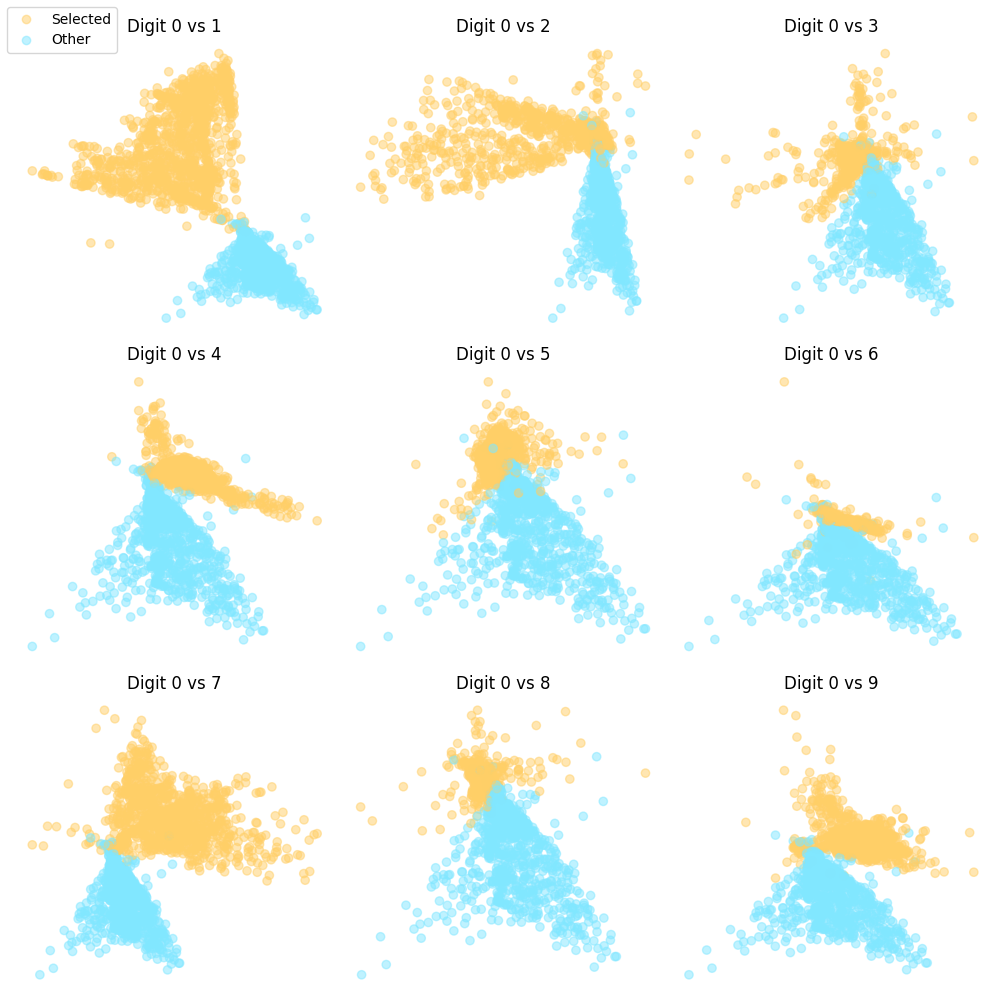

In [16]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
other_digits = [digit for digit in range(10) if digit != selected]

for i, other in enumerate(other_digits):
    ax = axes[i // 3, i % 3]
    mask = (y_test == selected) | (y_test == other)
    latent_subset = latent[mask]
    labels_subset = y_test[mask]

    scatter = ax.scatter(
        latent_subset[:, 0],
        latent_subset[:, 1],
        c=(labels_subset == selected),
        cmap="managua",
        alpha=0.5
    )
    ax.set_title(f"Digit {selected} vs {other}")
    ax.axis("off")

fig.legend(
    handles=scatter.legend_elements()[0],
    labels=["Selected", "Other"],
    loc="upper left"
)
plt.tight_layout()
plt.show()

The plots should show moderately good clusters for most of the digit pairs.

Note that we did not perform any class predictions here; these clusters show the two-dimensional latent representations of the MNIST images learned by our autoencoder.

#### Optional: What Is a Mask?

In programming, a mask is a sequence of Boolean values (or zeros and ones in a bitmask) that is used to select or unselect values in a same-sized sequence.

In the code above, `(y_test == selected)` creates an array of true/false values: true at indices where the label in `y_test` equals the `selected` digit, and false at indices where the label does not equal the `selected` digit.

Likewise, as the masks are created within a `for` loop, on each iteration the `other` variable contains a digit that does not equal `selected`, and a mask is created with true values at indices where the label equals the `other` digit.

The two masks then have the Boolean OR operation (with the `|` "pipe" symbol) applied, which results in a new mask in which an index has a true value whenever either the first or second mask has a true value at that index.

```python
    (y_test == selected) | (y_test == other)
```

We can then use this mask to index on a same-sized array like `latent`, which will index the values that contain `selected` **or** `other` (since the two original masks were OR-ed together).

The result is that we can selectively pairwise plot two class labels at a time, which is much easier to read than all ten labels visualized together.

Masks are a very useful technique in programming broadly, but perhaps especially so in indexing NumPy arrays!

### Classifying the Latent Representations

Based on the clusters above, it appears that the latent representations preserve a considerable amount of class information - but is it enough to perform well on a classification task?

Since these representations were derived from the test set, we will split the test set itself into a train-test split and reserve most of the latent representations for training the model.

Notice that the number of "features" in the data is equal to the number of dimensions of the encoder's latent representation.

In [17]:
X_train_latent, X_test_latent, y_train, y_test = model_selection.train_test_split(
    latent,
    y[-test_size:],
    test_size=0.1,
    stratify=y[-test_size:],
    random_state=seed
)

X_train_latent.shape, y_train.shape, X_test_latent.shape, y_test.shape

((9000, 2), (9000,), (1000, 2), (1000,))

Let's set up a quick baseline; since there are 10 classes, we would expect it to achieve about 10% accuracy.

In [18]:
clf_dummy = dummy.DummyClassifier(strategy="most_frequent")
clf_dummy.fit(X_train_latent, y_train)
clf_dummy.score(X_test_latent, y_test)

0.114

To keep this section simple, we'll use a Random Forest classifier.

In [19]:
clf = ensemble.RandomForestClassifier(
    n_estimators=100,
    random_state=seed
)

clf.fit(X_train_latent, y_train)
y_pred = clf.predict(X_test_latent)

pd.DataFrame(
    metrics.classification_report(
        y_pred,
        y_test,
        output_dict=True)
).T

,precision,recall,f1-score,support
0,0.969388,0.931373,0.950000,102.000
1,1.000000,0.982759,0.991304,116.000
2,0.669903,0.793103,0.726316,87.000
3,0.712871,0.705882,0.709360,102.000
4,0.591837,0.552381,0.571429,105.000
5,0.505618,0.535714,0.520231,84.000
6,0.875000,0.840000,0.857143,100.000
7,0.825243,0.833333,0.829268,102.000
8,0.659794,0.646465,0.653061,99.000
9,0.584158,0.572816,0.578431,103.000


Let's also look at a confusion matrix.

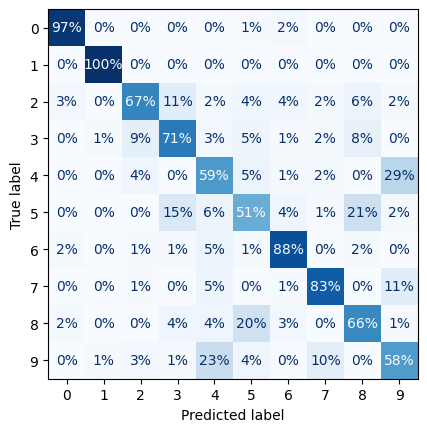

In [20]:
metrics.ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    normalize="true",
    values_format=".0%",
    cmap="Blues",
    colorbar=False,
)

Considering that the original 784-pixel inputs were each reduced to two dimensions, this outcome is not bad!

#### Try It Yourself

What if the dimensionality of the latent representations was a little bit larger? What if you used a feedforward network instead of a Random Forest classifier? Try to see how much you can increase accuracy without significantly increasing the size of the latent representation.

## Variational Autoencoders (VAE)

Now that we have seen how the autoencoder can produce low-dimensional codings that retain discriminatory power, we are going to make a minor adjustment that will allow the model to generate new samples based on the training data.

Note that typically in development we would instantiate a new encoder and decoder, rather than reuse the previous components. I reuse them here to highlight the similarity between the autoencoder and VAE.

First, let's review what the output layer of the encoder looked like. The `nn.Sequential` component can be indexed at the `-1` position to retrieve the output layer, just as if it were a Python list.

In [21]:
encoder[-1]

Linear(in_features=64, out_features=2, bias=True)

For our VAE, we actually need two features for every latent dimension - the mean and variance of the latent space - so we will double the size of the output layer to 4 neurons.

In [22]:
encoder[-1] = nn.Linear(in_features=encoder[-1].in_features, out_features=4)

Let's now restart the model by reinitializing the parameters.

In [23]:
encoder = encoder.apply(init_params).to(device)
decoder = decoder.apply(init_params).to(device)

We also need to reconfigure the optimizer with these new parameters. Since we no longer are using one sequential model, we can simply retrieve the parameters from the encoder and decoder individually and append them into a single list.

In [24]:
parameters = list(encoder.parameters()) + list(decoder.parameters())
optimizer = torch.optim.Adam(parameters, lr=learning_rate)

For the cost function, we actually want the sum of squared errors (SSE) rather than the mean so that this reconstruction loss is on the same scale as a latent loss we will also be calculating.

In [25]:
criterion = nn.MSELoss(reduction="sum")

### Training the Encoder and Decoder

In [26]:
encoder.train()
decoder.train()

for epoch in range(n_epochs):
    for X_batch in train_loader:
        X_batch = X_batch[0].to(device)

        latent = encoder(X_batch)
        mean, log_var = latent[:, :2], latent[:, 2:]

        std = torch.exp(0.5 * log_var)
        noise = torch.randn_like(std)
        y_pred = decoder(mean + std * noise)

        reconstruction_loss = criterion(y_pred, X_batch)
        latent_loss = -0.5 * torch.sum(
            1 + log_var - log_var.exp() - mean ** 2,
            dim=-1
        )
        loss = (reconstruction_loss + latent_loss.sum())

        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

This training loop has some important additions.

Instead of calling `model(X_batch)`, we call the encoder. This step produces the latent dimension (similar to principal components), which is then split into two halves:

- The first half will learn to capture the mean of each latent dimension
- The second half will learn to capture (the log of) the latent dimension's variance
  - We initially use the log of the variance as opposed to the standard deviation to allow the encoder to output negative values

We then generate and apply some random noise to the mean and standard deviation to get a noise vector, which serves as our sample of the latent space.

```python
    std = torch.exp(0.5 * log_var)
    noise = torch.randn_like(std)
    y_pred = decoder(mean + std * noise)
```

This noise vector is then passed into the decoder, which attempts to reconstruct the noise into 784 dimensions as if it were an MNIST digit. The reconstructed images for the batch are compared against the actual images from this batch to compute a reconstruction loss.

```python
    reconstruction_loss = criterion(y_pred, X_batch)
```

In learning to reduce the reconstruction loss, the encoder will provide a better estimate of the mean of the latent space. The reduction of the latent loss acts as a form of regularization on the latent space, pushing the mean toward zero and the variance toward one. As both losses are needed to improve the network, they are added together prior to backpropagation.

### Generating a Digit Image

We are now ready to generate an image that should resemble one of the MNIST handwritten digits!

Recall that the decoder still has an input layer size of two. We start with a base vector of zeros and add some noise to it before passing it to the decoder. Because the latent space was trained to approximate a normal distribution, adding noise to the base vector can serve as a sample from the latent space.

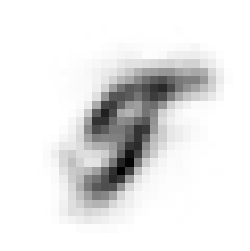

In [27]:
decoder.eval()
with torch.no_grad():
    base_vector = torch.tensor([[0.0, 0.0]], device=device)
    noise_vector = torch.randn_like(base_vector)
    generated_image = decoder(noise_vector).squeeze().cpu().numpy()

plt.figure(figsize=(3, 3))
plt.imshow(generated_image, cmap="gray_r")
plt.axis("off")
plt.show()

The fake images should, on average, look like good approximations of the real dataset, though they will be rather blurry.

As a next step, see if you can generate clearer images with some adjustments to the VAE's hyperparameters.

---

## Optional: Advanced Image Generation

This section does not pertain to the module project.

To use these models, we will need to import a few more packages.

In [28]:
%pip install --quiet pytorch-pretrained-biggan

In [29]:
import diffusers
import nltk
import PIL
import pytorch_pretrained_biggan as biggan

### Generative Adversarial Network (GAN)

GAN models make use of two networks: a generator, which tries to create realistic images, and a discriminator, which tries to flag images it receives as either real or having been created by the generator. The network that fails its task at any given step has its parameters adjusted.

Here, we use BigGAN, which is trained on the [ImageNet database](https://en.wikipedia.org/wiki/ImageNet).

#### ImageNet Class List

This GAN model is trained on a specific set of word classes, and will use a [WordNet dictionary](https://en.wikipedia.org/wiki/WordNet) to retrieve the ImageNet class closest to the word you provide.

If you would like to see the entire list of 1,000 ImageNet classes, run the cell below.

In [30]:
url = "https://storage.googleapis.com/download.tensorflow.org/data/imagenet_class_index.json"
sorted(pd.read_json(url).iloc[1].str.lower().str.replace("_", " ").values)

['abacus',
 'abaya',
 'academic gown',
 'accordion',
 'acorn',
 'acorn squash',
 'acoustic guitar',
 'admiral',
 'affenpinscher',
 'afghan hound',
 'african chameleon',
 'african crocodile',
 'african elephant',
 'african grey',
 'african hunting dog',
 'agama',
 'agaric',
 'aircraft carrier',
 'airedale',
 'airliner',
 'airship',
 'albatross',
 'alligator lizard',
 'alp',
 'altar',
 'ambulance',
 'american alligator',
 'american black bear',
 'american chameleon',
 'american coot',
 'american egret',
 'american lobster',
 'american staffordshire terrier',
 'amphibian',
 'analog clock',
 'anemone fish',
 'angora',
 'ant',
 'apiary',
 'appenzeller',
 'apron',
 'arabian camel',
 'arctic fox',
 'armadillo',
 'artichoke',
 'ashcan',
 'assault rifle',
 'australian terrier',
 'axolotl',
 'baboon',
 'backpack',
 'badger',
 'bagel',
 'bakery',
 'balance beam',
 'bald eagle',
 'balloon',
 'ballplayer',
 'ballpoint',
 'banana',
 'band aid',
 'banded gecko',
 'banjo',
 'bannister',
 'barbell',
 '

#### Download the WordNet Dictionary

In [31]:
nltk.download("wordnet")

[nltk_data] Downloading package wordnet to /root/nltk_data...


True

#### Generate the Image

In [32]:
gan_model = biggan.BigGAN.from_pretrained("biggan-deep-256").to(device)

100%|██████████| 715/715 [00:00<00:00, 1865004.58B/s]


Enter a word or short phrase for the image you wish to generate. This term does not need to be in the ImageNet class list, as WordNet will be used to find an appropriate match.

In [33]:
category = "red panda"

The truncation parameter provides a tradeoff between the variety and the quality of the image.

A lower truncation restricts values in the noise vector to be closer to the mean by cutting off outliers, which results in more stable but less original images; a higher truncation will have the opposite effect.

In [34]:
truncation = 0.5

We then create a class vector (based on our category string) and a noise vector before passing them to the GAN.

Rerunning the cell below will result in different images.

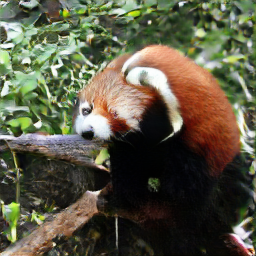

In [35]:
class_vector = torch.from_numpy(
    biggan.one_hot_from_names(
        [category],
        batch_size=1
    )
).to(device)

noise_vector = torch.from_numpy(
    biggan.truncated_noise_sample(
        truncation=truncation,
        batch_size=1
    )
).to(device)

with torch.no_grad():
    output = gan_model(noise_vector, class_vector, truncation).to("cpu")

output = (output + 1.0) / 2.0
output_image = output[0].mul(255).clamp(0, 255).byte().permute(1, 2, 0).numpy()

display(PIL.Image.fromarray(output_image))

### Diffusion Model

This diffusion model can be loaded from the [Hugging Face diffusers package](https://huggingface.co/docs/diffusers/index).

As is the case with many pre-trained models accessed through Hugging Face, very little setup is required here.

In [36]:
pipeline = diffusers.StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=torch.float16,
    low_cpu_mem_usage=True
).to(device)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Unlike the GAN model, we are not restricted by a set of class names.

Modify the prompt below to describe what kind of image you would like to generate.

In [37]:
prompt = "green sea turtle stained glass"

Run the pipeline to generate your image.

As this is hardly a frontier model, brace yourself for some wonkiness.

  0%|          | 0/50 [00:00<?, ?it/s]

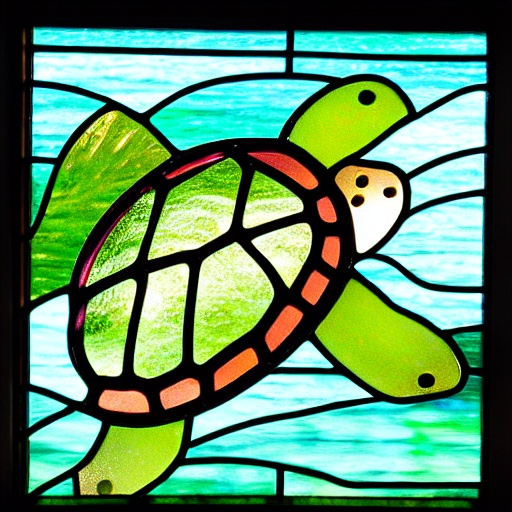

In [38]:
display(pipeline(prompt).images[0])

---

## Next Steps

Can you make modifications to the VAE's architecture to generate better digit images? What about using a CNN-based encoder and decoder? (See [Chapter 18 of the recommended text](https://learning.oreilly.com/library/view/hands-on-machine-learning/9798341607972/ch18.html) for an example; as a Foothill College student, you can [access O'Reilly Learning for free](https://libguides.fhda.edu/az/oreilly-safari).)

Notice that despite the additional representational and generative power of autoencoders, we did not need to introduce any new network components!

In this module's project, you will apply an encoder-decoder model to a task of your choice. See the project description in Canvas for a list of suggestions.